# Projet 5SPAR : Analyse de Sentiments sur Mastodon avec Apache Spark
**Objectif :** Entraîner un modèle de classification de texte (Machine Learning) sur un dataset labellisé, puis l'appliquer en batch sur un flux de données historiques Mastodon stocké dans PostgreSQL. Les résultats sont ensuite visualisés pour en extraire des insights métiers.

In [19]:
# Imports globaux
import os
import warnings
import psycopg
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

In [20]:
# Suppression des warnings liés à l'environnement
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Configuration de l'affichage graphique
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# Initialisation de la SparkSession
spark = SparkSession.builder \
    .appName('5SPAR-SentimentAnalysis') \
    .config('spark.sql.session.timeZone', 'UTC') \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.postgresql:postgresql:42.6.0") \
    .getOrCreate()

spark.sparkContext.setLogLevel('WARN')
print("Environnement initialisé avec succès.")

Environnement initialisé avec succès.


## Partie 4 : Analyse de sentiments avec Spark MLlib
### 4.1 Chargement et préparation des données d'entraînement (Kaggle)
Nous utilisons le dataset *Sentiment140* contenant 1,6 million de tweets labellisés pour entraîner notre modèle.

In [21]:
# Chargement du CSV Kaggle (Cible: col 0, Texte: col 5)
kaggle_df = spark.read.csv("training.1600000.processed.noemoticon.csv", header=False, inferSchema=True)
kaggle_df = kaggle_df.select(F.col("_c0").alias("target"), F.col("_c5").alias("text"))

# Formatage des labels pour Spark MLlib (1.0 = Positif, 0.0 = Négatif)
dataset = kaggle_df.withColumn("label", F.when(F.col("target") == 4, 1.0).otherwise(0.0))

# Séparation Train (80%) / Test (20%)
train_data, test_data = dataset.randomSplit([0.8, 0.2], seed=42)
print(f"Volume d'entraînement : {train_data.count()} lignes.")

Volume d'entraînement : 1280224 lignes.


### 4.2 Construction et évaluation du pipeline ML
Le traitement du texte inclut la tokénisation, le retrait des mots vides, et l'application d'un TF-IDF avant la régression logistique.

In [22]:
# Création des étapes du pipeline
tokenizer = Tokenizer(inputCol="text", outputCol="words")
remover = StopWordsRemover(inputCol=tokenizer.getOutputCol(), outputCol="filtered_words")
vectorizer = CountVectorizer(inputCol=remover.getOutputCol(), outputCol="rawFeatures")
idf = IDF(inputCol=vectorizer.getOutputCol(), outputCol="features")
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=10)

pipeline = Pipeline(stages=[tokenizer, remover, vectorizer, idf, lr])

# Entraînement
print("Entraînement du modèle en cours...")
model = pipeline.fit(train_data)

# Évaluation sur le jeu de test
predictions_test = model.transform(test_data)
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator.evaluate(predictions_test)
print(f"Précision (Accuracy) sur le jeu de test : {accuracy * 100:.2f}%")

Entraînement du modèle en cours...


26/10/06 13:34:11 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
26/10/06 13:34:21 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
26/10/06 13:34:22 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:33 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:34 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:46 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:47 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:48 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:49 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:50 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:51 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/10/06 13:34:52 WARN DAGScheduler: Broadcasting larg

Précision (Accuracy) sur le jeu de test : 75.18%


### 4.3 Inférence batch sur PostgreSQL
Application du modèle entraîné sur l'historique brut de Mastodon et sauvegarde des prédictions.

In [23]:
# Paramètres de connexion PostgreSQL
pg_host = os.getenv('PGHOST', 'postgres')
pg_db = os.getenv('PGDATABASE', 'mastodon')
pg_user = os.getenv('PGUSER', 'mastodon')
pg_password = os.getenv('PGPASSWORD', 'local_demo_change_me')

jdbc_url = f"jdbc:postgresql://{pg_host}:5432/{pg_db}"
connection_properties = {"user": pg_user, "password": pg_password, "driver": "org.postgresql.Driver"}

# Chargement, inférence et sauvegarde
mastodon_df = spark.read.jdbc(url=jdbc_url, table="toots", properties=connection_properties)
mastodon_predictions = model.transform(mastodon_df)

final_results = mastodon_predictions.withColumn(
    "sentiment_label",
    F.when(F.col("prediction") == 1.0, "Positive").otherwise("Negative")
).select("instance", "id", "created_at", "text", "username", "sentiment_label")

final_results.coalesce(2).write \
    .mode("overwrite") \
    .jdbc(url=jdbc_url, table="toots_sentiments", properties=connection_properties)

print("Inférence terminée. Résultats sauvegardés dans 'toots_sentiments'.")

Inférence terminée. Résultats sauvegardés dans 'toots_sentiments'.


26/10/06 13:35:16 WARN DAGScheduler: Broadcasting large task binary with size 9.0 MiB


## Partie 5 : Data visualisation
Exploitation de la base de données via Pandas pour générer des insights métiers.

In [24]:
# Définition de la fonction d'extraction SQL
conninfo = f"host={pg_host} dbname={pg_db} user={pg_user} password={pg_password}"

def load_data(query):
    with psycopg.connect(conninfo) as conn:
        return pd.read_sql_query(query, conn)

print("Prêt pour l'analyse visuelle.")

Prêt pour l'analyse visuelle.


### 5.1 Distribution globale des sentiments

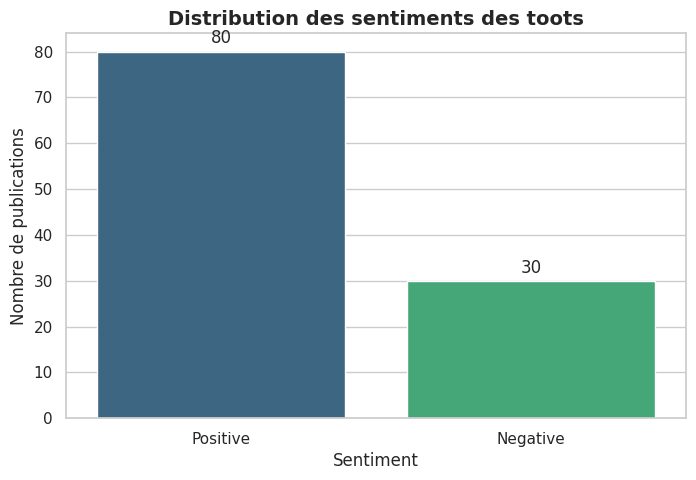

In [25]:
df_sentiments = load_data("SELECT sentiment_label, COUNT(*) as count FROM toots_sentiments GROUP BY sentiment_label")

plt.figure(figsize=(8, 5))

# On récupère l'axe dans la variable ax
ax = sns.barplot(
    data=df_sentiments, 
    x='sentiment_label', 
    y='count', 
    hue='sentiment_label', 
    palette='viridis', 
    legend=False
)

# Affiche les valeurs au-dessus de chaque barre
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distribution des sentiments des toots', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment')
plt.ylabel('Nombre de publications')
plt.show()

### 5.2 Fréquence des publications en temps réel

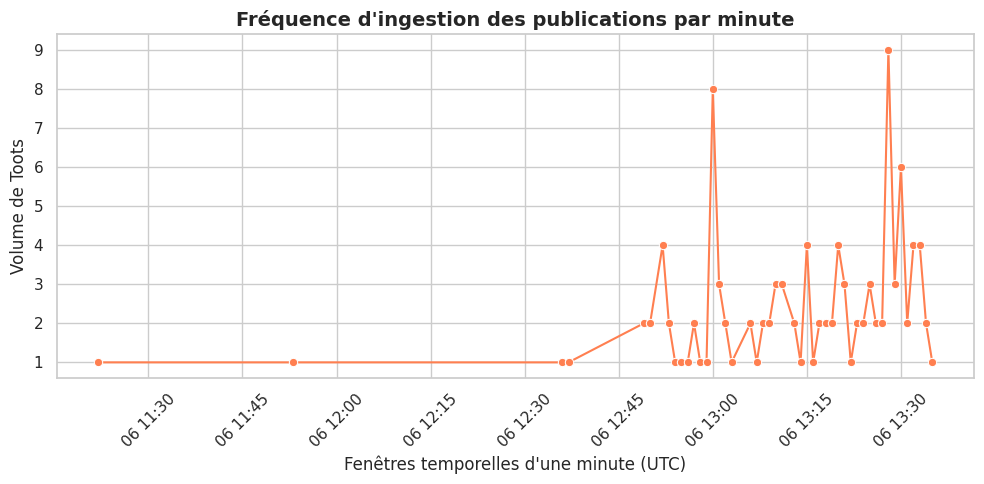

In [26]:
df_freq = load_data("SELECT window_start, toot_count FROM window_stats ORDER BY window_start")

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_freq, x='window_start', y='toot_count', marker='o', color='coral')
plt.title("Fréquence d'ingestion des publications par minute", fontsize=14, fontweight='bold')
plt.xlabel("Fenêtres temporelles d'une minute (UTC)")
plt.ylabel('Volume de Toots')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.3 Analyse des tendances : Top 10 des hashtags

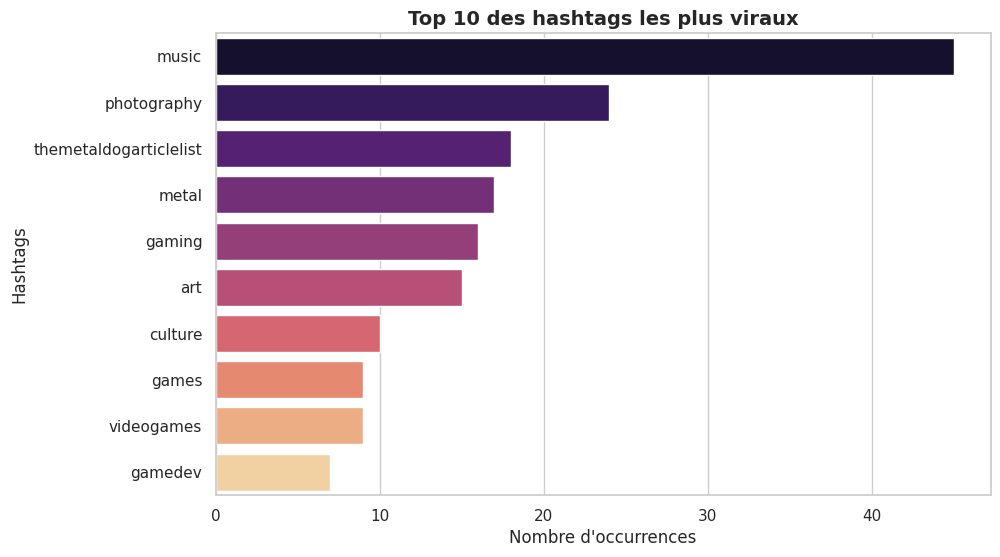

In [27]:
query_hashtags = """
SELECT unnest(hashtags) as tag, COUNT(*) as count 
FROM toots 
GROUP BY tag 
ORDER BY count DESC 
LIMIT 10
"""
df_tags = load_data(query_hashtags)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_tags, x='count', y='tag', hue='tag', palette='magma', legend=False)
plt.title('Top 10 des hashtags les plus viraux', fontsize=14, fontweight='bold')
plt.xlabel('Nombre d\'occurrences')
plt.ylabel('Hashtags')
plt.show()

### 5.4 Comportement utilisateurs : heatmap d'activité

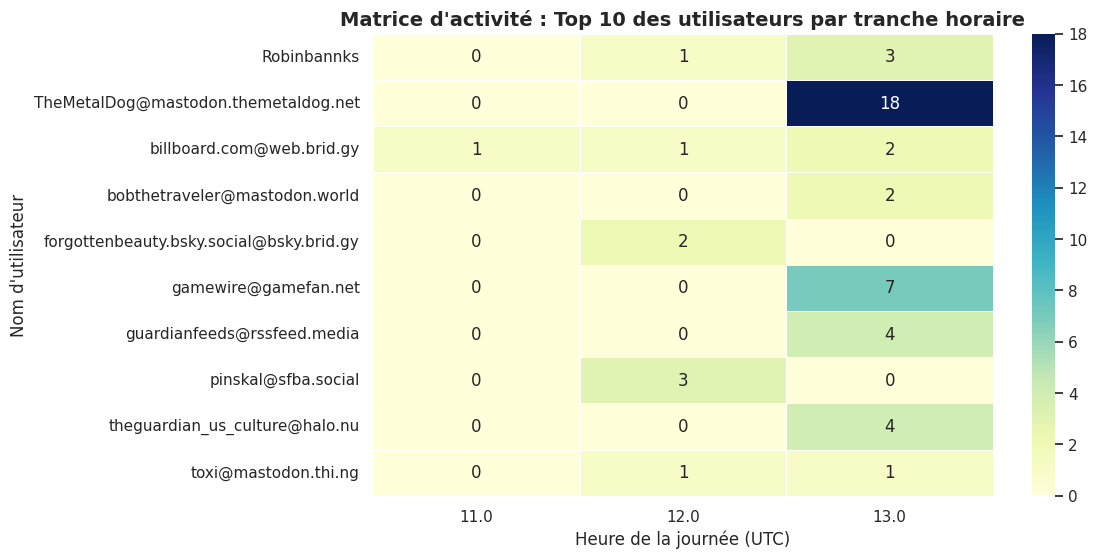

In [28]:
query_activity = """
SELECT username, EXTRACT(HOUR FROM created_at) as hour, COUNT(*) as toot_count
FROM toots
WHERE username IN (
    SELECT username FROM toots GROUP BY username ORDER BY COUNT(*) DESC LIMIT 10
)
GROUP BY username, hour
"""
df_activity = load_data(query_activity)

if not df_activity.empty:
    pivot_activity = df_activity.pivot(index="username", columns="hour", values="toot_count").fillna(0)
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_activity, cmap="YlGnBu", annot=True, fmt=".0f", linewidths=.5)
    plt.title('Matrice d\'activité : Top 10 des utilisateurs par tranche horaire', fontsize=14, fontweight='bold')
    plt.xlabel('Heure de la journée (UTC)')
    plt.ylabel('Nom d\'utilisateur')
    plt.show()
else:
    print("Volume de données insuffisant pour générer la Heatmap.")

### 5.5 Social listening : Évolution de la polarité en temps réel

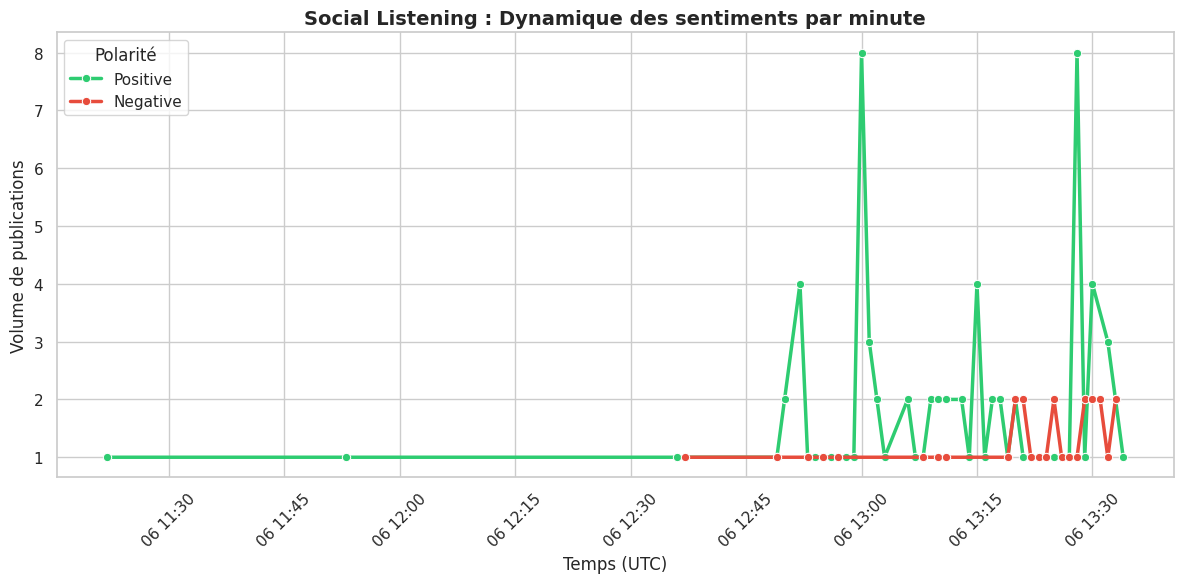

In [29]:
# Agrégation temporelle directement via PostgreSQL (DATE_TRUNC)
query_timeline = """
SELECT 
    DATE_TRUNC('minute', created_at) as timeline, 
    sentiment_label, 
    COUNT(*) as volume 
FROM toots_sentiments 
GROUP BY timeline, sentiment_label 
ORDER BY timeline
"""
df_timeline = load_data(query_timeline)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_timeline, 
    x='timeline', 
    y='volume', 
    hue='sentiment_label', 
    palette={'Positive': '#2ecc71', 'Negative': '#e74c3c'}, 
    linewidth=2.5,
    marker='o'
)
plt.title('Social Listening : Dynamique des sentiments par minute', fontsize=14, fontweight='bold')
plt.xlabel('Temps (UTC)')
plt.ylabel('Volume de publications')
plt.xticks(rotation=45)
plt.legend(title='Polarité')
plt.tight_layout()
plt.show()

### 5.6 Analyse comportementale : Longueur du texte vs sentiment

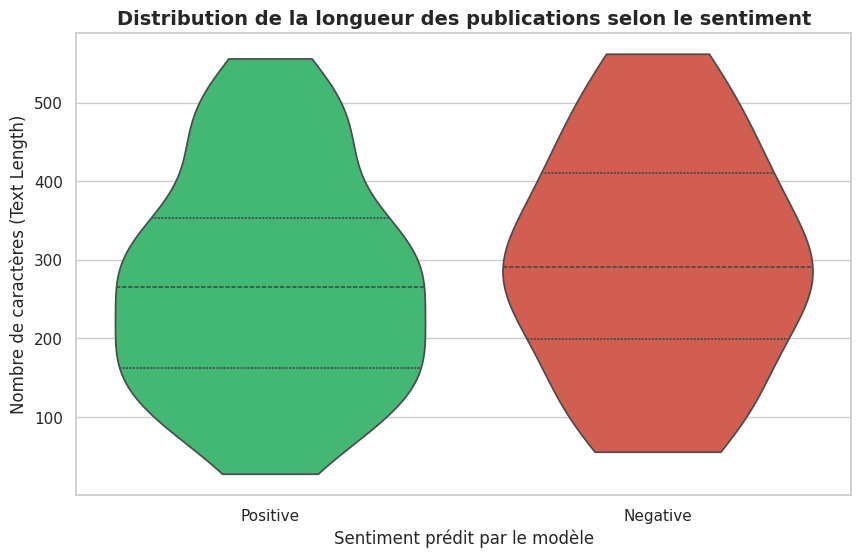

In [31]:
# Jointure SQL entre la table des prédictions et la table historique
query_behavior = """
SELECT ts.sentiment_label, t.text_length
FROM toots_sentiments ts
JOIN toots t ON ts.id = t.id AND ts.instance = t.instance
WHERE t.text_length IS NOT NULL
"""
df_behavior = load_data(query_behavior)

plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df_behavior, 
    x='sentiment_label', 
    y='text_length', 
    hue='sentiment_label',
    palette={'Positive': '#2ecc71', 'Negative': '#e74c3c'},
    inner='quartile',
    legend=False,
    cut=0
)
plt.title('Distribution de la longueur des publications selon le sentiment', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment prédit par le modèle')
plt.ylabel('Nombre de caractères (Text Length)')
plt.show()